<a href="https://colab.research.google.com/github/ogorgodze/PythonCodes/blob/main/Capital_for_Model_Risk_GH.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

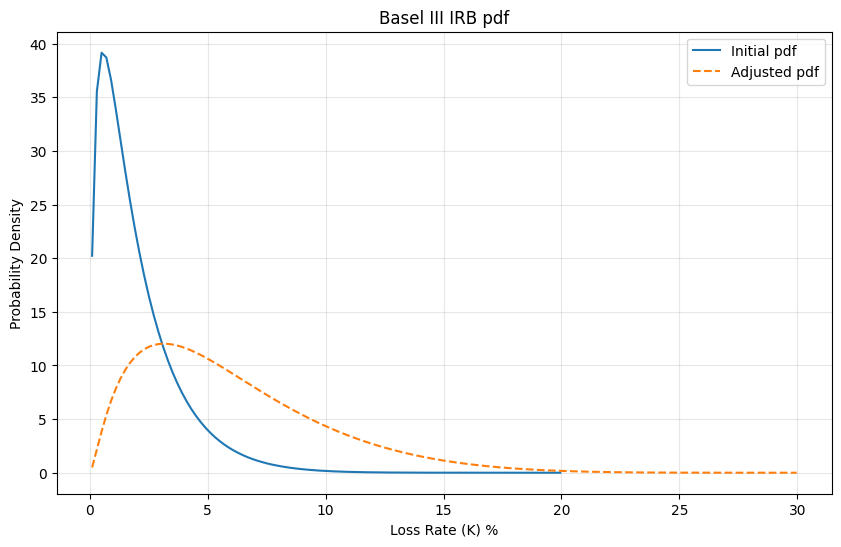

Portfolio ECL changed from 2 percent to 6 percent
Portfolio Capital changed from 9 percent to 16 percent


In [19]:
# additional capital due to model effor
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Define fixed parameters
PD=0.1

PD_1 = 0.1  # Original PD
PD_2 = 0.2  # Revised PD

LGD_1 = 0.2  # Original Loss Given Default
LGD_2 = 0.3  # Revised Loss Given Default
R = 0.2    # Asset Correlation


K_values = np.linspace(0.001, 0.4, 200)

def calculate_pdf(K, PD, R, LGD):
    phi_inv_K_LGD = norm.ppf(K / LGD)
    phi_inv_PD = norm.ppf(PD)
    numerator = np.sqrt((1 - R) / R) * norm.pdf((np.sqrt(1 - R) * phi_inv_K_LGD - phi_inv_PD) / np.sqrt(R))
    denominator = LGD * norm.pdf(phi_inv_K_LGD)
    return numerator / denominator

# Calculate PDF for PD = 0.05
pdf_1 = calculate_pdf(K_values, PD_1, R, LGD_1)

# Calculate PDF for PD = 0.10
pdf_2 = calculate_pdf(K_values, PD_2, R, LGD_2)

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(K_values * 100, pdf_1, label='Initial pdf')
plt.plot(K_values * 100, pdf_2, label='Adjusted pdf', linestyle='--')

plt.xlabel('Loss Rate (K) %')
plt.ylabel('Probability Density')
plt.title('Basel III IRB pdf')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Calculate capital addon
def calculate_K_999(PD, R, LGD):
    arg = (norm.ppf(PD) + np.sqrt(R) * norm.ppf(0.999)) / np.sqrt(1 - R)
    loss_rate = LGD * norm.cdf(arg)
    return loss_rate - PD* LGD

K_1 = calculate_K_999(PD_1, R, LGD_1)
K_2 = calculate_K_999(PD_2, R, LGD_2)

ECL_1 = PD_1*LGD_1
ECL_2 = PD_2*LGD_2


print('Portfolio ECL changed from', round((ECL_1)*100),'percent', 'to' ,round((ECL_2)*100),'percent')
print('Portfolio capital changed from', round((K_1)*100),'percent', 'to' ,round((K_2)*100),'percent')
